# Analisis Statistik Feedback Pelayanan Kelurahan Geluran
**Catatan:** seluruh data pada notebook ini adalah **data dummy (simulasi)** untuk pengembangan prototipe, bukan feedback warga sungguhan. Hasil/angka tidak boleh dibaca sebagai kondisi nyata pelayanan.

## 1. Persiapan (mengambil kode dari repo)

In [1]:
import os
REPO = "Studpen-Mini-Project-Feedback-Masyarakat"
if not os.path.exists(REPO):
    !git clone https://github.com/Anggiee-sys/{REPO}.git
%cd {REPO}
!pip -q install seaborn


Cloning into 'Studpen-Mini-Project-Feedback-Masyarakat'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 27 (delta 5), reused 22 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 17.02 KiB | 4.25 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/Studpen-Mini-Project-Feedback-Masyarakat


In [2]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import analisis as a
from validasi import cek_kualitas_data, ringkas_kualitas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)


## 2. Memuat data dan cek kualitas

In [3]:
df = pd.read_csv("data/dummy_feedback.csv")
print(df.shape)
df.head()

(290, 9)


,Timestamp,Periode,Layanan,Rating_Kecepatan,Rating_Sikap,Rating_Prosedur,Rating_Informasi,Kritik_Saran,Sumber_Data
0,2026-08-10 08:32:57,2026-08,Surat Keterangan,5,5,4,5,NaN,dummy
1,2026-08-10 09:47:34,2026-08,SKTM (Surat Keterangan Tidak Mampu),2,4,2,2,"Syarat berkas berubah-ubah, mohon dijelaskan s...",dummy
2,2026-08-10 10:30:31,2026-08,Konsultasi Warga,5,4,5,4,"Pelayanan sudah baik, terima kasih.",dummy
3,2026-08-10 11:05:43,2026-08,SKTM (Surat Keterangan Tidak Mampu),3,3,4,3,NaN,dummy
4,2026-08-11 09:59:29,2026-08,Konsultasi Warga,5,4,3,3,Mohon dibuatkan brosur atau informasi yang leb...,dummy


In [4]:
print(ringkas_kualitas(cek_kualitas_data(df)))
print(df["Sumber_Data"].value_counts())

Data bersih: 290 baris, tidak ada masalah ditemukan.
Sumber_Data
dummy    290
Name: count, dtype: int64


In [5]:
d = a.siapkan(df, sumber="dummy")
a.ringkasan_umum(d)

{'jumlah_responden': 290,
 'skor_rata_rata': 3.64,
 'jumlah_layanan': 5,
 'jumlah_periode': 4,
 'n_kecil': False}

## 3. Statistik deskriptif per aspek
Rata-rata, median, simpangan baku (Std), skewness, dan selang kepercayaan 95% (CI95).

In [6]:
a.statistik_per_aspek(d)

,Kolom,Aspek,n,Rata-rata,Median,Std,Skewness,CI95 bawah,CI95 atas
0,Rating_Kecepatan,Kecepatan pelayanan,290,3.53,3.0,0.93,-0.18,3.42,3.64
1,Rating_Sikap,Sikap petugas,290,4.08,4.0,0.76,-0.47,3.99,4.17
2,Rating_Prosedur,Kejelasan prosedur,290,3.45,4.0,0.94,-0.23,3.34,3.56
3,Rating_Informasi,Kelengkapan informasi,290,3.49,3.0,0.83,-0.11,3.40,3.59


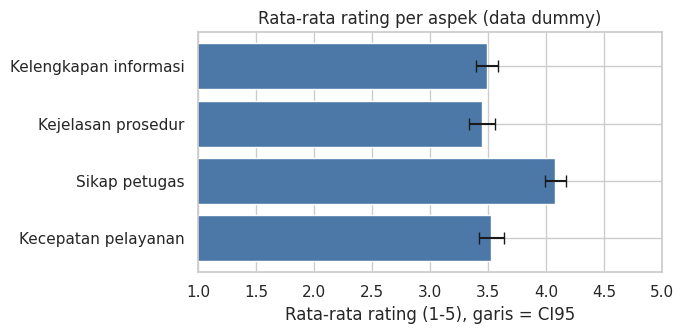

In [7]:
st = a.statistik_per_aspek(d)
fig, ax = plt.subplots(figsize=(7,3.5))
ax.barh(st["Aspek"], st["Rata-rata"], xerr=[st["Rata-rata"]-st["CI95 bawah"], st["CI95 atas"]-st["Rata-rata"]], color="#4C78A8", capsize=4)
ax.set_xlim(1,5); ax.set_xlabel("Rata-rata rating (1-5), garis = CI95"); ax.set_title("Rata-rata rating per aspek (data dummy)")
plt.tight_layout(); plt.show()

## 4. Distribusi rating

In [8]:
dist = a.distribusi_rating(d)
dist

,1,2,3,4,5
Aspek,,,,,
Kecepatan pelayanan,2.1,8.3,40.3,33.1,16.2
Sikap petugas,0.0,2.4,17.6,49.7,30.3
Kejelasan prosedur,1.7,14.5,33.4,37.9,12.4
Kelengkapan informasi,1.0,7.9,42.4,37.9,10.7


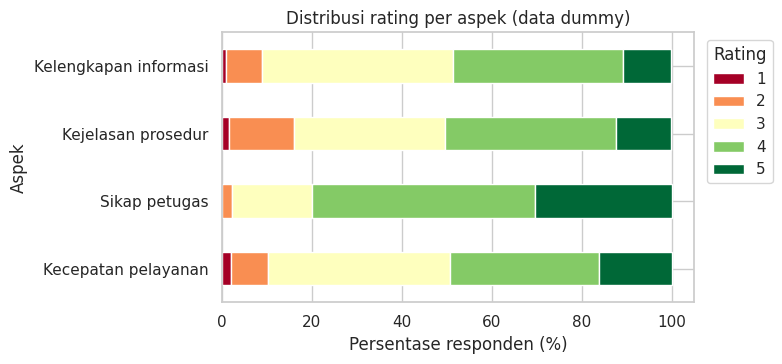

In [9]:
ax = dist.plot(kind="barh", stacked=True, figsize=(8,3.8), colormap="RdYlGn")
ax.set_xlabel("Persentase responden (%)"); ax.legend(title="Rating", bbox_to_anchor=(1.01,1), loc="upper left")
ax.set_title("Distribusi rating per aspek (data dummy)")
plt.tight_layout(); plt.show()

## 5. Perbandingan antarlayanan

In [10]:
sl = a.skor_per_layanan(d)
sl

,Kecepatan pelayanan,Sikap petugas,Kejelasan prosedur,Kelengkapan informasi,Skor rata-rata,n
Layanan,,,,,,
Perubahan Data/Dokumen Kependudukan,3.22,3.91,2.78,3.32,3.31,76
SKTM (Surat Keterangan Tidak Mampu),3.03,3.92,3.43,3.08,3.37,65
Lainnya,3.70,4.10,3.80,3.60,3.80,20
Surat Keterangan,3.84,4.19,3.71,3.76,3.87,85
Konsultasi Warga,4.14,4.39,3.98,3.84,4.09,44


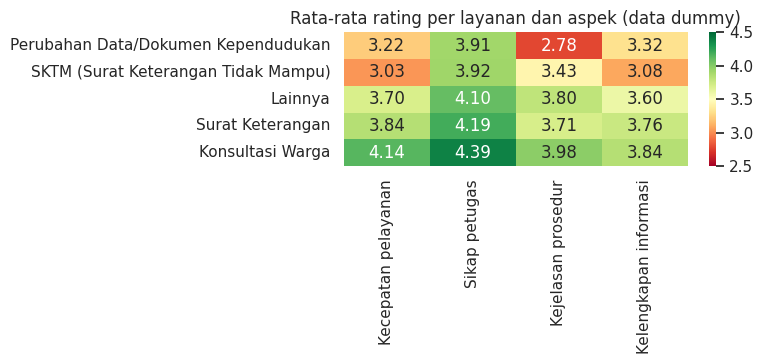

In [11]:
aspek_cols = [v for v in a.ASPEK.values()]
plt.figure(figsize=(8,3.8))
sns.heatmap(sl[aspek_cols], annot=True, fmt=".2f", cmap="RdYlGn", vmin=2.5, vmax=4.5)
plt.title("Rata-rata rating per layanan dan aspek (data dummy)"); plt.ylabel(""); plt.tight_layout(); plt.show()

## 6. Tren per periode

In [12]:
tr = a.tren_periode(d)
tr

,Kecepatan pelayanan,Sikap petugas,Kejelasan prosedur,Kelengkapan informasi,Skor rata-rata,n
Periode,,,,,,
2026-08,3.46,4.16,3.61,3.20,3.61,85
2026-09,3.37,3.94,3.43,3.44,3.55,70
2026-10,3.65,4.04,3.33,3.69,3.68,75
2026-11,3.67,4.17,3.38,3.72,3.73,60


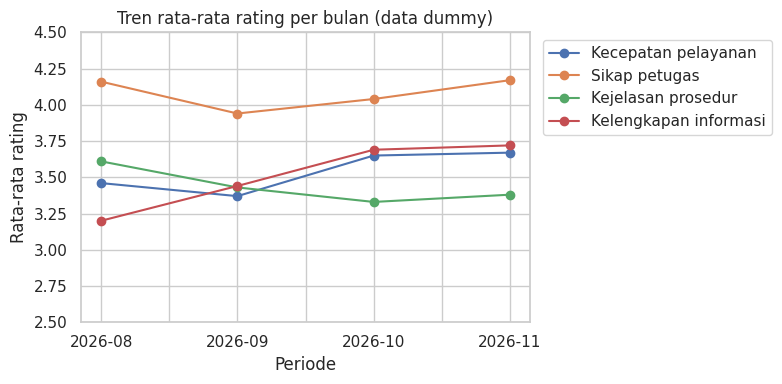

In [13]:
ax = tr[aspek_cols].plot(marker="o", figsize=(8,4))
ax.set_ylim(2.5,4.5); ax.set_ylabel("Rata-rata rating"); ax.set_title("Tren rata-rata rating per bulan (data dummy)")
ax.legend(bbox_to_anchor=(1.01,1), loc="upper left"); plt.tight_layout(); plt.show()

### Tren per layanan (aspek kecepatan)
Tren total relatif datar; perbedaan baru terlihat saat dipecah per layanan. Perhatikan juga jumlah isian per kelompok.

In [14]:
tl = a.tren_layanan(d, "Rating_Kecepatan")
display(tl)
display(a.jumlah_per_layanan_periode(d))

Layanan,Konsultasi Warga,Lainnya,Perubahan Data/Dokumen Kependudukan,SKTM (Surat Keterangan Tidak Mampu),Surat Keterangan
Periode,,,,,
2026-08,4.31,4.67,3.32,2.73,3.62
2026-09,4.00,3.40,3.17,2.57,3.74
2026-10,4.00,3.00,3.43,3.57,3.88
2026-11,4.20,3.50,2.94,3.64,4.18


Layanan,Konsultasi Warga,Lainnya,Perubahan Data/Dokumen Kependudukan,SKTM (Surat Keterangan Tidak Mampu),Surat Keterangan
Periode,,,,,
2026-08,13,6,19,26,21
2026-09,10,5,18,14,23
2026-10,11,5,21,14,24
2026-11,10,4,18,11,17


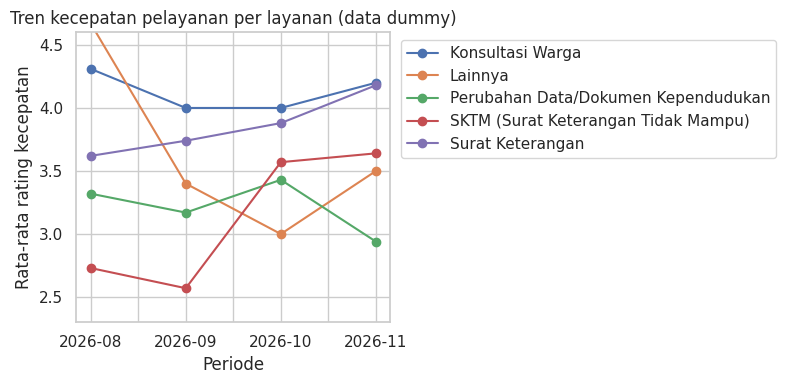

In [15]:
ax = tl.plot(marker="o", figsize=(8,4))
ax.set_ylim(2.3,4.6); ax.set_ylabel("Rata-rata rating kecepatan"); ax.set_title("Tren kecepatan pelayanan per layanan (data dummy)")
ax.legend(bbox_to_anchor=(1.01,1), loc="upper left"); plt.tight_layout(); plt.show()

## 7. Perbandingan periode terakhir dan aspek yang perlu perhatian

In [16]:
p = a.perubahan_periode(d)
print(p["periode_sebelum"], "->", p["periode_akhir"], "| n:", p["n_sebelum"], p["n_akhir"], "| layak dibandingkan:", p["layak"])
p["tabel"]

2026-10 -> 2026-11 | n: 75 60 | layak dibandingkan: True


,Aspek,Sebelumnya,Terakhir,Selisih
0,Kecepatan pelayanan,3.65,3.67,0.02
1,Sikap petugas,4.04,4.17,0.13
2,Kejelasan prosedur,3.33,3.38,0.05
3,Kelengkapan informasi,3.69,3.72,0.03


In [17]:
for x in a.daftar_perhatian(d):
    print("-", x["aspek"], ":", x["keterangan"])

- Kejelasan prosedur : rata-rata 3.45 (di bawah 3.5)
- Kelengkapan informasi : rata-rata 3.49 (di bawah 3.5)


## 8. Catatan interpretasi

> Seluruh angka berasal dari data dummy (simulasi, n = 290, Agustus–November 2026). Pola di bawah sengaja dibuat pada data simulasi untuk menguji bahwa modul analisis dapat mendeteksinya. Ini bukan kondisi nyata pelayanan Kelurahan Geluran.

**Per aspek**
- Sikap petugas adalah aspek dengan rata-rata tertinggi (sekitar 4,1). Sekitar 80% rating-nya bernilai 4–5.
- Kejelasan prosedur (sekitar 3,45) dan Kelengkapan informasi (sekitar 3,49) adalah yang terendah. Keduanya berada di bawah ambang perhatian 3,5 sehingga ditandai "perlu perhatian". Pada Kejelasan prosedur, sekitar 16% rating bernilai 1–2, paling banyak dibanding aspek lain.
- Kecepatan pelayanan berada di tengah (sekitar 3,5).
- Selang kepercayaan 95% tiap aspek sempit (lebar sekitar 0,2) karena n cukup besar, sehingga urutan aspek tergolong stabil.

**Per layanan**
- Perubahan Data/Dokumen Kependudukan dan SKTM adalah dua layanan dengan skor rata-rata terendah, dan Konsultasi Warga tertinggi.
- Pada Perubahan Data, aspek yang paling lemah adalah Kejelasan prosedur. Ini menunjukkan perlunya alur dan persyaratan yang lebih jelas pada layanan tersebut.

**Tren per periode**
- Skor rata-rata keseluruhan relatif datar (3,61 → 3,55 → 3,68 → 3,73). Perubahan baru terlihat saat dipecah per layanan.
- Kecepatan SKTM membaik dari 2,73 (Agustus) menjadi 3,64 (November).
- Kecepatan Perubahan Data turun dari 3,43 (Oktober) menjadi 2,94 (November). Selisih -0,49 melewati ambang penurunan 0,3, tetapi perlu dicek ulang pada data real karena jumlah isian per sel hanya sekitar 18.

**Keterbatasan**
- Data masih dummy. Hasil hanya menunjukkan bahwa modul analisis berfungsi.
- Layanan "Lainnya" hanya 4–6 isian per bulan, sehingga angka per bulannya tidak dipakai untuk kesimpulan.
- Analisis ini deskriptif. Penyebab perubahan skor tidak dapat disimpulkan dari angka saja.
- Setelah ada data real, analisis diulang dengan `sumber=["uji_coba","real"]` atau `"real"`.